# Mall Customer Segmentation

## 1. Import Libraries

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
Path("images").mkdir(exist_ok=True)


## 2. Load Dataset

In [2]:
df = pd.read_csv("Mall_Customers.csv")

df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 3. Explore Dataset

In [3]:
df.shape


(200, 5)

In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [5]:
df.isnull().sum()


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [6]:
df.duplicated().sum()


np.int64(0)

In [7]:
df.describe()


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## 4. Univariate Analysis

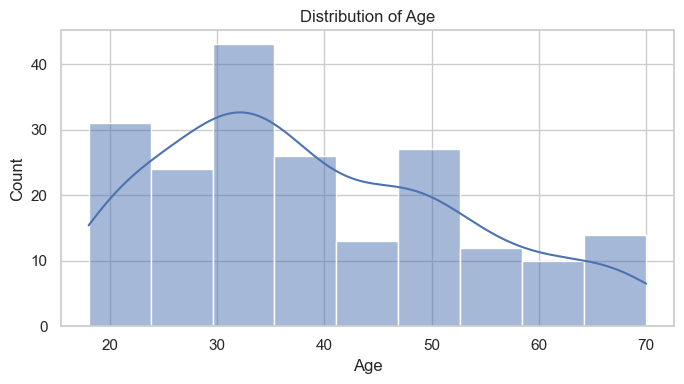

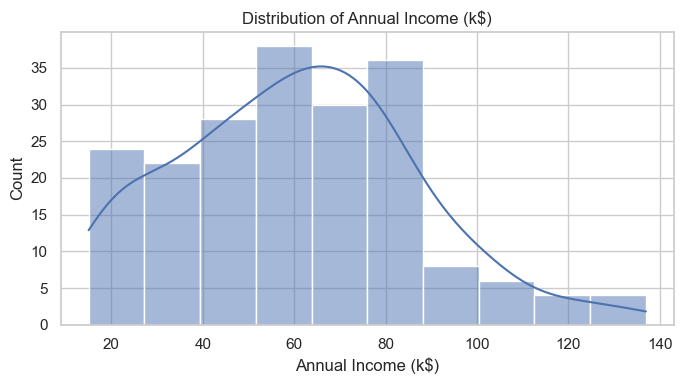

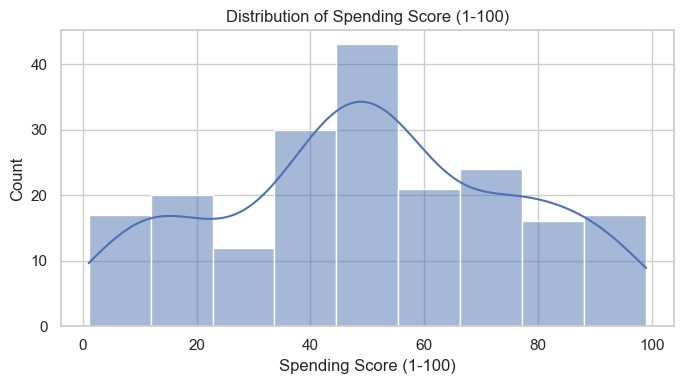

In [8]:
columns = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

for column in columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=column, kde=True)
    plt.title(f"Distribution of {column}")
    plt.tight_layout()
    plt.show()


In [9]:
df["Gender"].value_counts(normalize=True)


Gender
Female    0.56
Male      0.44
Name: proportion, dtype: float64

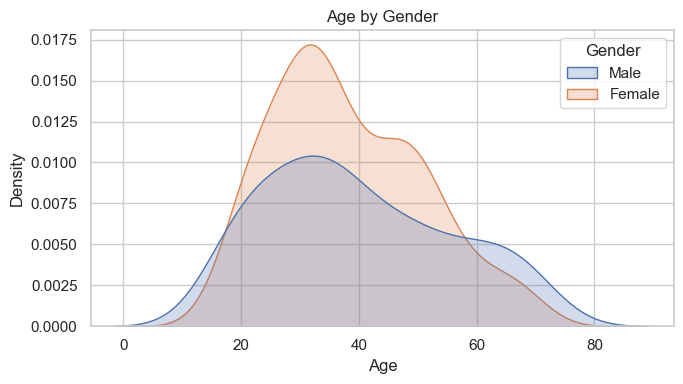

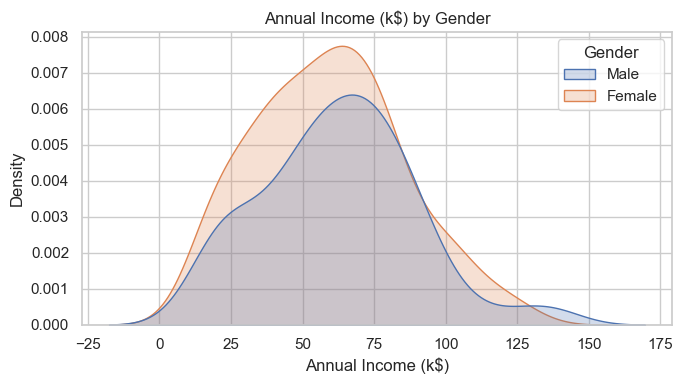

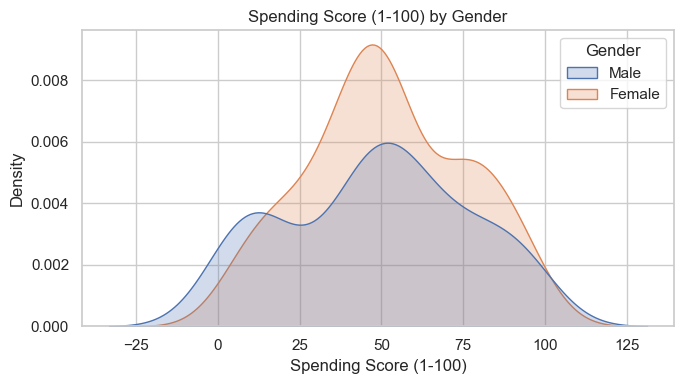

In [10]:
for column in columns:
    plt.figure(figsize=(7, 4))
    sns.kdeplot(data=df, x=column, hue="Gender", fill=True)
    plt.title(f"{column} by Gender")
    plt.tight_layout()
    plt.show()


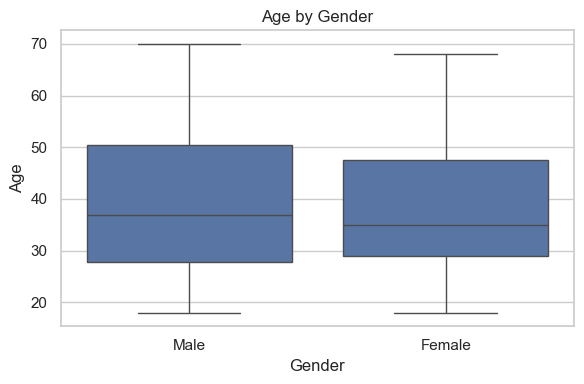

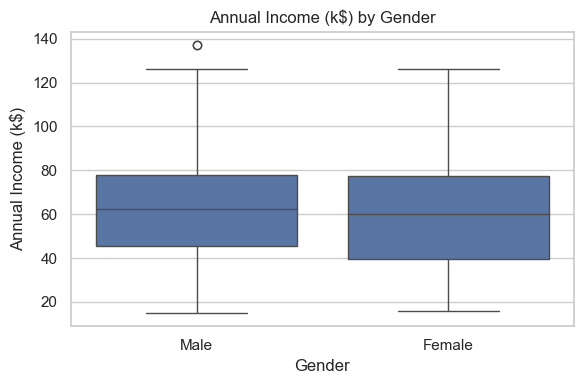

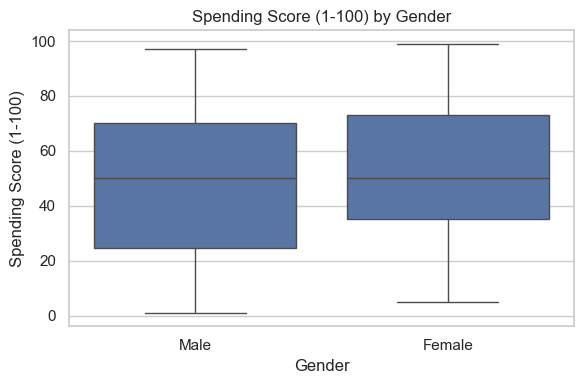

In [11]:
for column in columns:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x="Gender", y=column)
    plt.title(f"{column} by Gender")
    plt.tight_layout()
    plt.show()


## 5. Bivariate Analysis

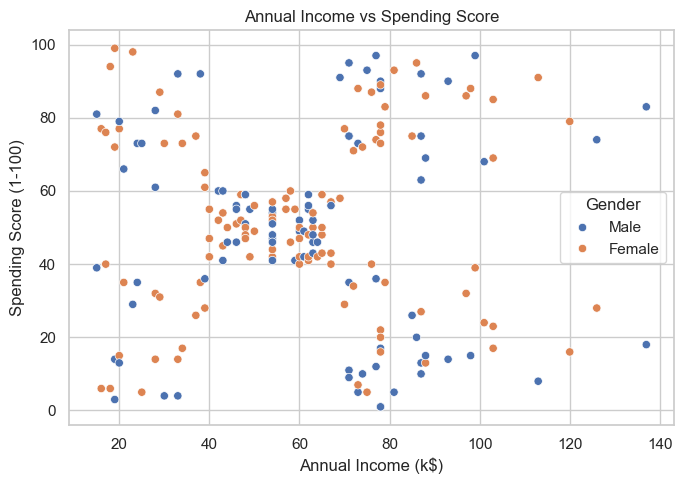

In [12]:
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Gender"
)
plt.title("Annual Income vs Spending Score")
plt.tight_layout()
plt.show()


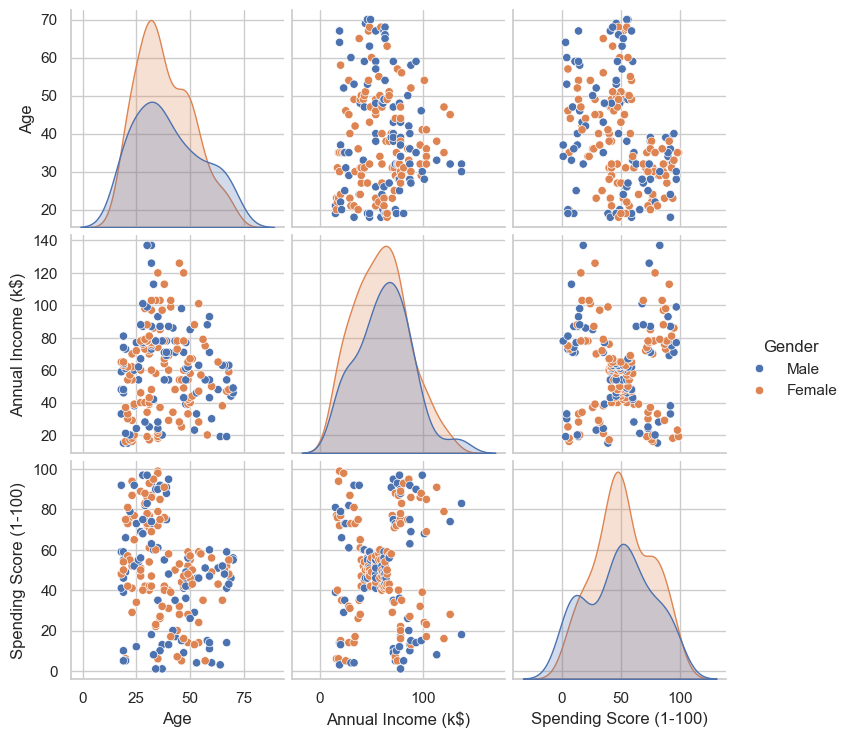

In [13]:
sns.pairplot(data=df, vars=columns, hue="Gender")
plt.show()


In [14]:
df[columns].corr()


,Age,Annual Income (k$),Spending Score (1-100)
Age,1.000000,-0.012398,-0.327227
Annual Income (k$),-0.012398,1.000000,0.009903
Spending Score (1-100),-0.327227,0.009903,1.000000


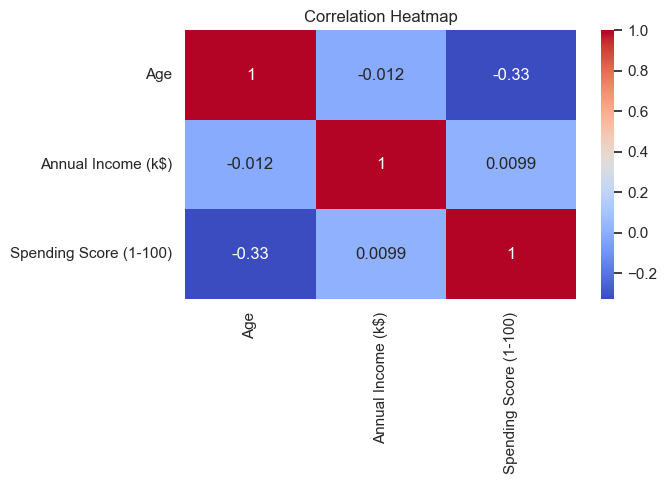

In [15]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[columns].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


In [16]:
df.groupby("Gender")[columns].mean().round(2)


,Age,Annual Income (k$),Spending Score (1-100)
Gender,,,
Female,38.10,59.25,51.53
Male,39.81,62.23,48.51


## 6. K-Means Evaluation Function

In [17]:
def evaluate_kmeans(X, k_values=range(2, 11)):
    results = []

    for k in k_values:
        model = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=10
        )
        labels = model.fit_predict(X)

        results.append({
            "K": k,
            "Inertia": model.inertia_,
            "Silhouette Score": silhouette_score(X, labels)
        })

    return pd.DataFrame(results)


def plot_evaluation(results, title):
    plt.figure(figsize=(7, 4))
    plt.plot(results["K"], results["Inertia"], marker="o")
    plt.xlabel("Number of Clusters")
    plt.ylabel("Inertia")
    plt.title(f"{title} - Elbow Method")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 4))
    plt.plot(results["K"], results["Silhouette Score"], marker="o")
    plt.xlabel("Number of Clusters")
    plt.ylabel("Silhouette Score")
    plt.title(f"{title} - Silhouette Score")
    plt.tight_layout()
    plt.show()

    display(results.round(3))


## 7. Univariate Clustering

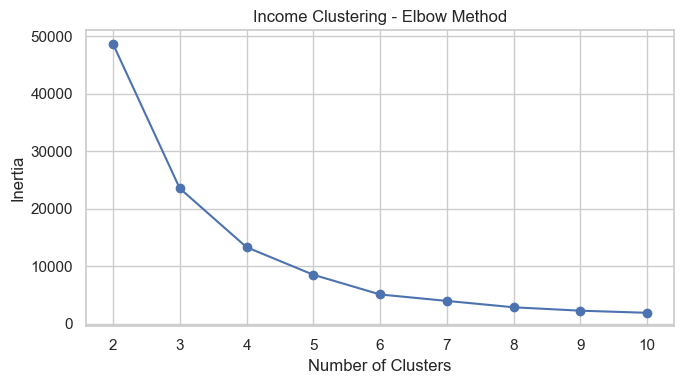

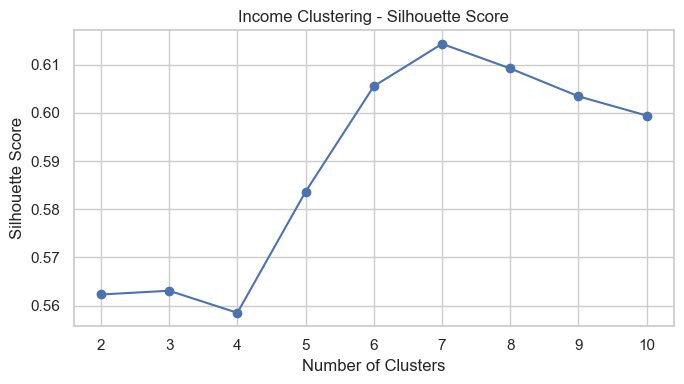

,K,Inertia,Silhouette Score
0,2,48660.889,0.562
1,3,23517.331,0.563
2,4,13278.113,0.558
3,5,8481.496,0.584
4,6,5050.905,0.606
5,7,3931.988,0.614
6,8,2822.500,0.609
7,9,2229.590,0.603
8,10,1862.870,0.599


In [18]:
income_features = df[["Annual Income (k$)"]]

income_evaluation = evaluate_kmeans(income_features)
plot_evaluation(income_evaluation, "Income Clustering")


In [19]:
income_model = KMeans(
    n_clusters=3,
    random_state=RANDOM_STATE,
    n_init=10
)

df["Income Cluster"] = income_model.fit_predict(income_features)

df["Income Cluster"].value_counts().sort_index()


Income Cluster
0    74
1    90
2    36
Name: count, dtype: int64

In [20]:
df.groupby("Income Cluster")[columns].mean().round(2)


,Age,Annual Income (k$),Spending Score (1-100)
Income Cluster,,,
0,39.50,33.49,50.23
1,38.72,67.09,50.00
2,37.83,99.89,50.64


## 8. Bivariate Clustering

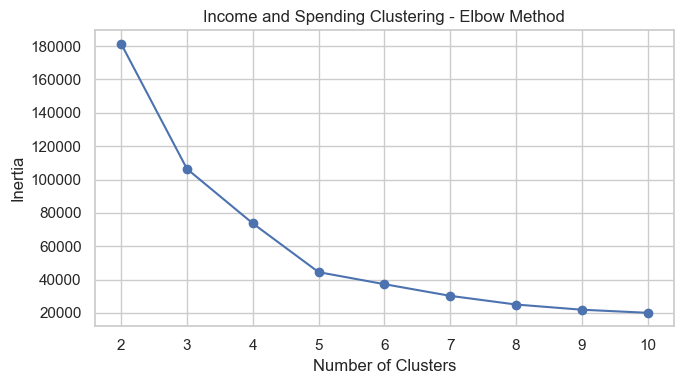

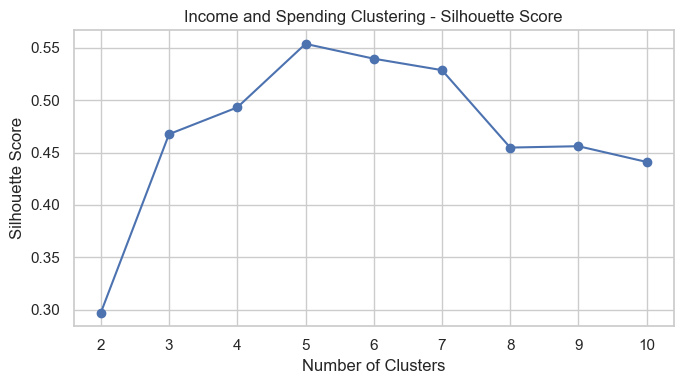

,K,Inertia,Silhouette Score
0,2,181363.596,0.297
1,3,106348.373,0.468
2,4,73679.789,0.493
3,5,44448.455,0.554
4,6,37233.815,0.540
5,7,30241.344,0.529
6,8,25036.418,0.455
7,9,21916.795,0.456
8,10,20072.071,0.441


In [21]:
bivariate_features = df[
    ["Annual Income (k$)", "Spending Score (1-100)"]
]

bivariate_evaluation = evaluate_kmeans(bivariate_features)
plot_evaluation(bivariate_evaluation, "Income and Spending Clustering")


In [22]:
bivariate_model = KMeans(
    n_clusters=5,
    random_state=RANDOM_STATE,
    n_init=10
)

df["Spending and Income Cluster"] = bivariate_model.fit_predict(
    bivariate_features
)

df["Spending and Income Cluster"].value_counts().sort_index()


Spending and Income Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

In [23]:
df.groupby("Spending and Income Cluster")[columns].mean().round(2)


,Age,Annual Income (k$),Spending Score (1-100)
Spending and Income Cluster,,,
0,42.72,55.30,49.52
1,32.69,86.54,82.13
2,25.27,25.73,79.36
3,41.11,88.20,17.11
4,45.22,26.30,20.91


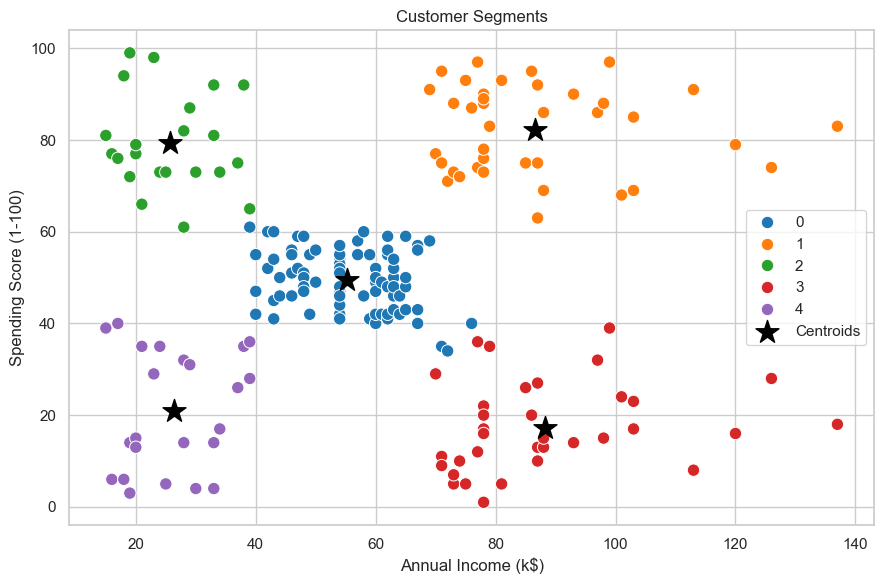

In [24]:
centers = pd.DataFrame(
    bivariate_model.cluster_centers_,
    columns=["Annual Income (k$)", "Spending Score (1-100)"]
)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Spending and Income Cluster",
    palette="tab10",
    s=80
)

plt.scatter(
    centers["Annual Income (k$)"],
    centers["Spending Score (1-100)"],
    marker="*",
    s=300,
    color="black",
    label="Centroids"
)

plt.title("Customer Segments")
plt.legend()
plt.tight_layout()
plt.show()


In [25]:
pd.crosstab(
    df["Spending and Income Cluster"],
    df["Gender"],
    normalize="index"
).round(3)


Gender,Female,Male
Spending and Income Cluster,,
0,0.593,0.407
1,0.538,0.462
2,0.591,0.409
3,0.457,0.543
4,0.609,0.391


## 9. Multivariate Clustering

In [26]:
multivariate_features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)",
    "Gender"
]

X = df[multivariate_features].copy()
X["Gender"] = X["Gender"].map({"Female": 0, "Male": 1})

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=multivariate_features,
    index=df.index
)

X_scaled.head()


,Age,Annual Income (k$),Spending Score (1-100),Gender
0,-1.424569,-1.738999,-0.434801,1.128152
1,-1.281035,-1.738999,1.195704,1.128152
2,-1.352802,-1.700830,-1.715913,-0.886405
3,-1.137502,-1.700830,1.040418,-0.886405
4,-0.563369,-1.662660,-0.395980,-0.886405


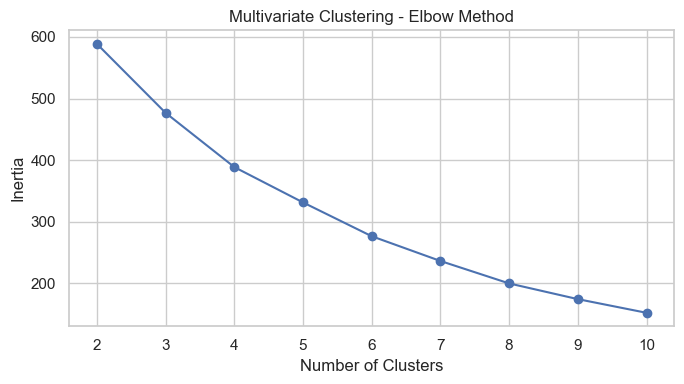

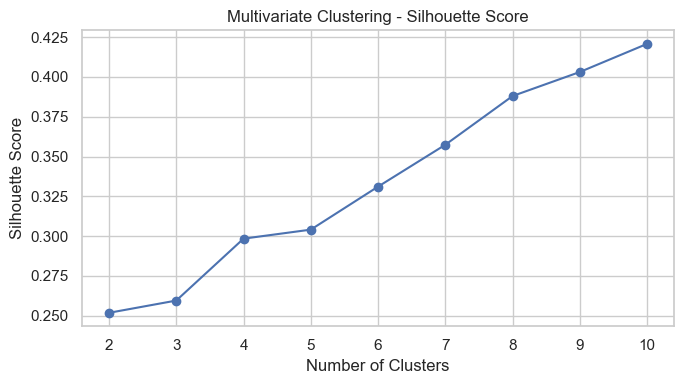

,K,Inertia,Silhouette Score
0,2,588.803,0.252
1,3,476.788,0.260
2,4,388.718,0.298
3,5,331.310,0.304
4,6,276.412,0.331
5,7,236.205,0.357
6,8,199.750,0.388
7,9,174.235,0.403
8,10,152.030,0.421


In [27]:
multivariate_evaluation = evaluate_kmeans(X_scaled)
plot_evaluation(multivariate_evaluation, "Multivariate Clustering")


In [28]:
multivariate_model = KMeans(
    n_clusters=5,
    random_state=RANDOM_STATE,
    n_init=10
)

df["Multivariate Cluster"] = multivariate_model.fit_predict(X_scaled)

df["Multivariate Cluster"].value_counts().sort_index()


Multivariate Cluster
0    39
1    29
2    43
3    54
4    35
Name: count, dtype: int64

In [29]:
df.groupby("Multivariate Cluster")[columns].mean().round(2)


,Age,Annual Income (k$),Spending Score (1-100)
Multivariate Cluster,,,
0,32.69,86.54,82.13
1,36.48,89.52,18.00
2,49.81,49.23,40.07
3,24.91,39.72,61.20
4,55.71,53.69,36.77


In [30]:
pd.crosstab(
    df["Multivariate Cluster"],
    df["Gender"],
    normalize="index"
).round(3)


Gender,Female,Male
Multivariate Cluster,,
0,0.538,0.462
1,0.552,0.448
2,1.000,0.000
3,0.593,0.407
4,0.000,1.000


## 10. Export Results

In [31]:
df.to_csv("Mall_Customers_with_Clusters.csv", index=False)

df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Income Cluster,Spending and Income Cluster,Multivariate Cluster
0,1,Male,19,15,39,0,4,3
1,2,Male,21,15,81,0,2,3
2,3,Female,20,16,6,0,4,3
3,4,Female,23,16,77,0,2,3
4,5,Female,31,17,40,0,4,3
